# Custom Inputs and Reusable Pipelines

When no built-in generator fits, write your own `Input` subclass; it then combines with every operator and transformation of the composable API. This tutorial shows how, and then builds a small pipeline that generates a batch of trials (one stimulus, independent noise per trial) and runs them through a model.

## 1. Setup

In [1]:
import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

import braintools.input as inp

brainstate.environ.set(dt=0.1 * u.ms)
dt_ms = 0.1


def t_of(x):
    return np.arange(len(x)) * dt_ms

## 2. Subclassing `Input`

A subclass needs two things:

1. call `super().__init__(duration)` in its constructor;
2. implement `generate()`, returning an array with `self.n_steps` samples along the first axis.

Inside `generate()`, `self.dt` is the current time step and `self.n_steps` the number of samples ($\lceil \text{duration}/dt \rceil$). Work with quantities so units are checked; convert to plain numbers only where an operation needs them.

The example below is a train of alpha-function synaptic currents, $I(t) = \sum_k A \frac{t - t_k}{\tau} e^{1 - (t - t_k)/\tau}$ for $t > t_k$, whose peak is $A$ at $\tau$ after each spike.

In [2]:
class AlphaTrain(inp.Input):
    # Sum of alpha-function currents triggered at the given spike times.

    def __init__(self, spike_times, amplitude, tau, duration):
        super().__init__(duration)
        self.spike_times = spike_times
        self.amplitude = amplitude
        self.tau = tau

    def generate(self):
        t = np.arange(self.n_steps) * self.dt  # Quantity, same unit as dt
        s = (t[:, None] - self.spike_times[None, :]) / self.tau  # dimensionless, (steps, n_spikes)
        s = np.asarray(u.maybe_decimal(s))
        kernel = np.where(s > 0, s * np.exp(1 - s), 0.0)
        return kernel.sum(axis=1) * self.amplitude


epsc = AlphaTrain(spike_times=[20, 25, 30, 80] * u.ms, amplitude=0.1 * u.nA, tau=3 * u.ms, duration=150 * u.ms)
x = epsc()
print(f"{x.shape[0]} samples, unit {u.get_unit(x)}")
single = AlphaTrain([20] * u.ms, 0.1 * u.nA, 3 * u.ms, 150 * u.ms)()
print(f"single alpha peaks at {float(single.max().to_decimal(u.nA)):.3f} nA, {t_of(single)[np.argmax(single)] - 20:.1f} ms after the spike")

1500 samples, unit nA
single alpha peaks at 0.100 nA, 3.0 ms after the spike


The new class inherits everything from `Input`: arithmetic with other inputs, `&`, `shift`, `smooth`, caching, and so on. It also follows the global `dt`.

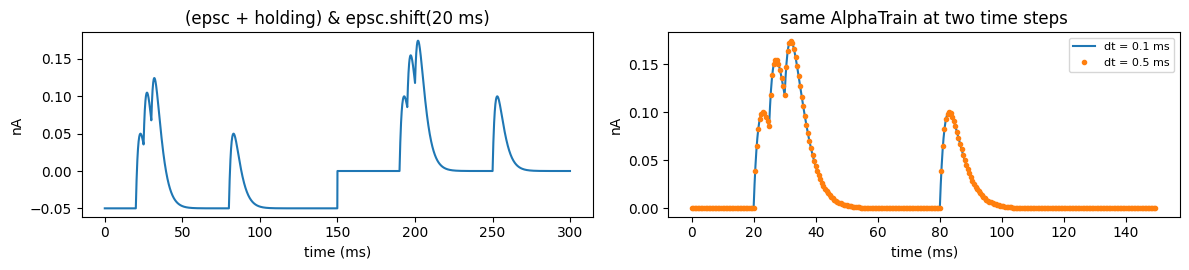

In [3]:
holding = inp.Constant([(-0.05 * u.nA, 150 * u.ms)])
protocol = (epsc + holding) & epsc.shift(20 * u.ms)

with brainstate.environ.context(dt=0.5 * u.ms):
    coarse = AlphaTrain([20, 25, 30, 80] * u.ms, 0.1 * u.nA, 3 * u.ms, 150 * u.ms)()

fig, axes = plt.subplots(1, 2, figsize=(12, 2.8))
axes[0].plot(t_of(protocol()), protocol().to_decimal(u.nA))
axes[0].set_title("(epsc + holding) & epsc.shift(20 ms)")
axes[1].plot(t_of(x), x.to_decimal(u.nA), label="dt = 0.1 ms")
axes[1].plot(np.arange(len(coarse)) * 0.5, coarse.to_decimal(u.nA), "o", ms=3, label="dt = 0.5 ms")
axes[1].set_title("same AlphaTrain at two time steps")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("time (ms)")
    ax.set_ylabel("nA")
fig.tight_layout()
plt.show()

For a one-off post-processing step a subclass is not needed: `apply(f)` (or `inp.Transformed(input, f)`) wraps any function of the generated array, and the result is still an `Input`.

In [4]:
rectified_noise = inp.OUProcess(0.0 * u.nA, 0.2 * u.nA, 10 * u.ms, 200 * u.ms, seed=0).apply(lambda v: u.math.maximum(v, 0 * u.nA))
print(type(rectified_noise).__name__, "min:", rectified_noise().min())

Transformed min: 0. nA


## 3. A Pipeline: Repeated Trials With Independent Noise

A *pipeline* here is simply a function that returns an `Input` built from parameters. Two rules make it reproducible and statistically correct:

- give every stochastic component an explicit `seed` derived from the trial number, so the batch can be regenerated exactly;
- build a **new** stochastic object per trial; reusing one object would reuse its cached realization in every trial.

The function below combines a step stimulus with background synaptic noise.

In [5]:
def make_trial(trial, stim_amp=0.15 * u.nA, noise_std=0.08 * u.nA, base_seed=1000):
    stimulus = inp.Step([0 * u.nA, stim_amp, 0 * u.nA], [0, 100, 300] * u.ms, duration=400 * u.ms)
    background = inp.OUProcess(0.12 * u.nA, noise_std, tau=5 * u.ms, duration=400 * u.ms, seed=base_seed + trial)
    return stimulus + background


n_trials = 40
I = u.math.stack([make_trial(k)() for k in range(n_trials)], axis=1)  # (steps, trials)
print("batch shape:", I.shape)
print("rebuilding trial 3 gives identical input:", bool(u.math.all(make_trial(3)() == I[:, 3])))
stimulus = inp.Step([0 * u.nA, 0.15 * u.nA, 0 * u.nA], [0, 100, 300] * u.ms, duration=400 * u.ms)()
noise_only = (I - stimulus[:, None]).to_decimal(u.nA)
corr = np.corrcoef(noise_only.T)[np.triu_indices(n_trials, 1)]
print(f"mean correlation between the noise of different trials: {corr.mean():+.4f}")

batch shape: (4000, 40)
rebuilding trial 3 gives identical input: True
mean correlation between the noise of different trials: +0.0002


The batch drives a population of identical leaky integrate-and-fire neurons in one vectorized loop. The baseline drive alone stays below threshold on average ($R \cdot 0.12$ nA $= 12$ mV against a 20 mV gap), so spikes during the baseline are caused by noise; the step adds 15 mV and makes firing reliable.

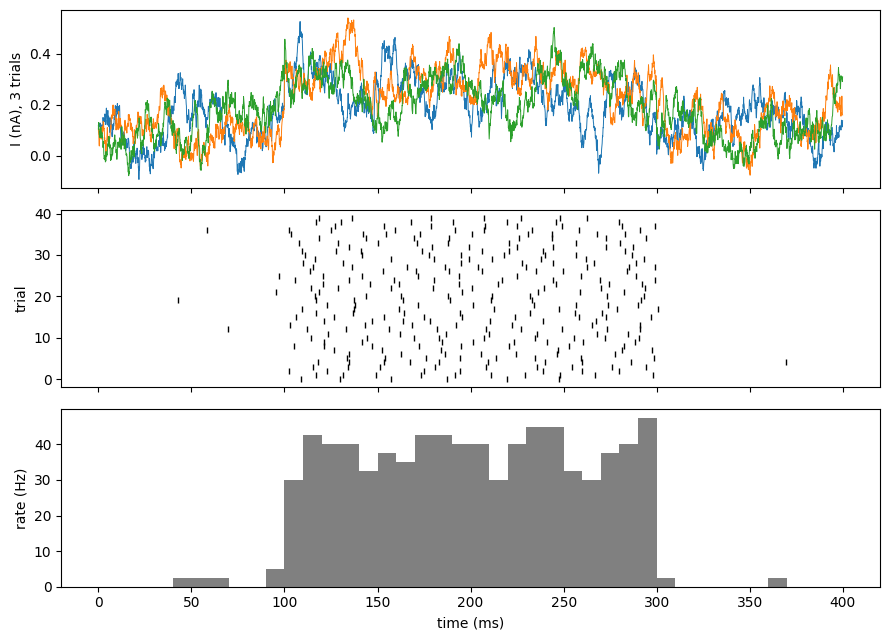

mean rate during the step 38.5 Hz, outside 0.9 Hz


In [6]:
tau, R, E_L, V_th = 20 * u.ms, 100 * u.Mohm, -70 * u.mV, -50 * u.mV
dt = brainstate.environ.get_dt()
V = u.math.full(n_trials, -70.0) * u.mV
spikes = np.zeros(I.shape, dtype=bool)
for i, I_t in enumerate(I):
    V = V + dt / tau * (-(V - E_L) + R * I_t)
    spikes[i] = np.asarray(V >= V_th)
    V = u.math.where(spikes[i], E_L, V)

bin_ms = 10
psth = spikes.reshape(-1, int(bin_ms / dt_ms), n_trials).sum(axis=(1, 2)) / n_trials / (bin_ms * 1e-3)

fig, axes = plt.subplots(3, 1, figsize=(9, 6.5), sharex=True)
for k in range(3):
    axes[0].plot(t_of(I), I[:, k].to_decimal(u.nA), lw=0.7)
axes[0].set_ylabel("I (nA), 3 trials")
rows, cols = np.nonzero(spikes.T)
axes[1].plot(cols * dt_ms, rows, "|", color="k", ms=4)
axes[1].set_ylabel("trial")
axes[2].bar(np.arange(len(psth)) * bin_ms, psth, width=bin_ms, align="edge", color="0.5")
axes[2].set_ylabel("rate (Hz)")
axes[2].set_xlabel("time (ms)")
fig.tight_layout()
plt.show()

during = spikes[1000:3000].sum() / n_trials / 0.2
outside = (spikes[:1000].sum() + spikes[3000:].sum()) / n_trials / 0.2
print(f"mean rate during the step {during:.1f} Hz, outside {outside:.1f} Hz")

## 4. Practical Notes

- **Inputs are arrays per step.** Generate them once before the simulation loop and index them by step; regenerate only when `dt` changes.
- **Seeds.** Stochastic generators without a `seed` draw from NumPy's global state; pass explicit seeds for anything you need to reproduce.
- **Caching.** An `Input` caches its array. Reusing an object reuses its realization; build new objects (or call with `recompute=True`) for fresh noise.
- **Units.** Keep currents as quantities through the pipeline; unit errors then surface at construction or generation time instead of as silently mis-scaled currents.
- **Keyword arguments.** Several functional and composable generators order their parameters differently, so pass them by name.

## Summary

- Subclass `Input`, call `super().__init__(duration)`, and implement `generate()` with `self.n_steps` samples; the subclass then supports all operators and transformations.
- `apply` / `Transformed` cover one-off post-processing.
- A pipeline is a function that returns an `Input`; derive seeds from the trial number and build new stochastic objects per trial.